# Demostración del modelo final

Este cuaderno propone el nombre de un plato peruano a partir de una fotografía completa. El clasificador YOLO26m-cls distingue **40 clases conocidas**; la variante `cls` clasifica la imagen completa, no localiza objetos ni identifica ingredientes. Al final verá una ficha orientativa de la receta y sus límites.

Solo necesita el código, los archivos de clases e ingredientes, los pesos finales y una foto. No se entrena ni se evalúa el conjunto de prueba aquí. Para usar su propia imagen, cambie `IMAGE_PATH` en el paso 1 y ejecute todas las celdas.

## 1. Configurar las rutas

El código busca primero el proyecto local desde la raíz del repositorio, del proyecto o de `notebooks`. En Colab, si solo abrió este cuaderno, descargará el paquete de código. El dataset completo no es necesario para esta demostración. Puede editar las rutas antes de continuar.

In [1]:
from pathlib import Path

CODE_URL = "https://github.com/miguelsff/maestria-ia-uni-ciclo-2-redes-neuronales/releases/download/v1.0-final/Equipo3_Codigo.zip"
DATASET_URL = "https://data.mendeley.com/public-api/zip/hxhbbm497d/download/3"
WEIGHTS_URL = "https://github.com/miguelsff/maestria-ia-uni-ciclo-2-redes-neuronales/releases/download/v1.0-final/perufoodnet_best.pt"
PROJECT_OVERRIDE = None  # Ejemplo: Path("/content/perufoodnet")
WEIGHTS_PATH = None  # Ruta opcional a los pesos finales
IMAGE_PATH = None  # None usa la foto incluida; o indique Path("ruta/a/foto.jpg")


Si las rutas locales no existen, Colab preparará los archivos en su sesión. Fuera de Colab, indique la ubicación del proyecto y los pesos en la celda anterior.

In [2]:
import sys
import zipfile
from urllib.request import urlretrieve
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False
candidatos = [Path.cwd(), *Path.cwd().parents]
if PROJECT_OVERRIDE is not None:
    candidatos.insert(0, Path(PROJECT_OVERRIDE))
proyectos = [p for base in candidatos for p in (base, base / "examen-final" / "entregables" / "3.3 Código")
             if (p / "src" / "predict.py").is_file()]
if not proyectos and EN_COLAB:
    destino = Path("/content/perufoodnet_codigo")
    destino.mkdir(parents=True, exist_ok=True)
    archivo = destino / "codigo.zip"
    urlretrieve(CODE_URL, archivo)
    with zipfile.ZipFile(archivo) as paquete:
        for miembro in paquete.infolist():
            if not (destino / miembro.filename).resolve().is_relative_to(destino.resolve()):
                raise ValueError("El paquete contiene una ruta fuera de su carpeta.")
        paquete.extractall(destino)
    proyectos = [p.parent.parent for p in destino.rglob("predict.py") if p.parent.name == "src"]
if not proyectos:
    raise FileNotFoundError("No se encontró el proyecto. Configure PROJECT_OVERRIDE.")
PROJECT = proyectos[0].resolve()
sys.path.insert(0, str(PROJECT / "src"))
print("Proyecto encontrado.")


Proyecto encontrado.


La salida identifica la carpeta utilizada. En Colab se instalan las bibliotecas necesarias para inferencia; Colab y las descargas están preparados, pero no se ejecutaron.

In [3]:
if EN_COLAB:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch==2.11.0", "torchvision==0.26.0", "ultralytics==8.4.202", "pandas==3.1.0", "matplotlib==3.11.2", "pillow==12.3.0", "gdown==5.2.0"])


## 2. Preparar y comprobar los pesos

Los **pesos** son los valores aprendidos por la red. ¿Conviene reutilizar una red ya entrenada y adaptar solo su última capa, o ajustar toda la red a los platos? Reutilizar conocimientos de una red previamente entrenada se llama transferencia de aprendizaje. Con **extractor fijo**, se entrena solo la última capa y se conservan las demás; con **ajuste completo**, se entrenan también las capas que extraen características. El archivo final se comprueba automáticamente antes de cargarlo. Si falta en Colab, se descarga desde la URL configurada.

Si no indica `WEIGHTS_PATH`, se buscan primero los pesos junto al README del proyecto y luego en la ruta local de la campaña. Una ruta indicada tiene prioridad.

In [4]:
from resources import resolve_weights
if WEIGHTS_PATH is None:
    pesos_adjuntos = PROJECT / "perufoodnet_best.pt"
    pesos_campana = Path("E:/MIA203-Grupo3/reinicio-20261105-r03/matriz-convergencia/perufoodnet_best.pt")
    WEIGHTS_PATH = pesos_adjuntos if pesos_adjuntos.is_file() else pesos_campana
else:
    WEIGHTS_PATH = Path(WEIGHTS_PATH)
sesion = Path("/content") if EN_COLAB else Path.home() / "perufoodnet_data"
WEIGHTS_PATH = resolve_weights(WEIGHTS_PATH, WEIGHTS_URL, sesion / "perufoodnet_best.pt")
print("Integridad de los pesos finales comprobada.")


Integridad de los pesos finales comprobada.


Una confirmación indica que el archivo coincide con el checkpoint final.

### ¿Qué ocurrió al comparar las estrategias?

Para comparar en igualdad de condiciones, la tabla muestra F1 macro de **validación** con 40 fotos de entrenamiento por clase, tasa 0,0001 y semilla 42. La semilla controla el azar de una corrida. F1 macro va de 0 a 1 y da igual peso a las 40 clases: combina precisión (proporción correcta entre las fotos propuestas para una clase) y cobertura (proporción reconocida entre las fotos reales de esa clase). Un valor mayor es mejor.

| Modelo | Extractor fijo: última capa | Ajuste completo |
|---|---:|---:|
| ResNet-18 | 0,7027 | 0,8804 |
| YOLO26m-cls | 0,8355 | 0,8879 |

En esta comparación puntual, ajustar toda la red obtuvo un F1 mayor para ambas familias. Son resultados de una sola semilla; no son por sí solos la regla de selección. Fuente: `results/comparacion_misma_tasa.csv`.

La selección final comparó, entre las configuraciones de 40 fotos por clase, las medias de **tres semillas** con la tasa elegida mediante validación. YOLO26m-cls con ajuste completo obtuvo 0,8903 ± 0,0076; ResNet-18 completo obtuvo 0,8810 ± 0,0103. El símbolo ± indica desviación estándar entre semillas, no una probabilidad de acierto ni una garantía de superioridad estadística. Se eligió YOLO26m-cls; el checkpoint oficial es el de la semilla 42.

La validación sirve para elegir configuraciones. Una vez fijada la selección, se evaluaron 600 fotos reservadas para **prueba**: 543 aciertos, exactitud 0,905 y F1 macro 0,9043. La exactitud es la proporción de aciertos. Las 50 predicciones inciertas también cuentan. Fotos de una misma ración podrían aparecer en distintos conjuntos, lo que puede elevar estas métricas.

Cada corrida tenía un máximo de 200 épocas y se detenía tras 10 sin mejorar el F1 de validación. La semilla 42 alcanzó su mejor valor en la época 8 y terminó en la 18; se conserva la época 8. Entrenamiento y evaluación completos se ejecutan en `src` según el README; aquí solo se consultan resultados guardados.


## 3. Observar la foto

La imagen incluida es el primer acierto no incierto del CSV de prueba, elegido en su orden original. Es una ilustración de inferencia, no una nueva evaluación. Fuente: [PeruFoodNet v3](https://data.mendeley.com/datasets/hxhbbm497d/3), ruta original `Aguadito/71_Aguadito.jpg`, licencia [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

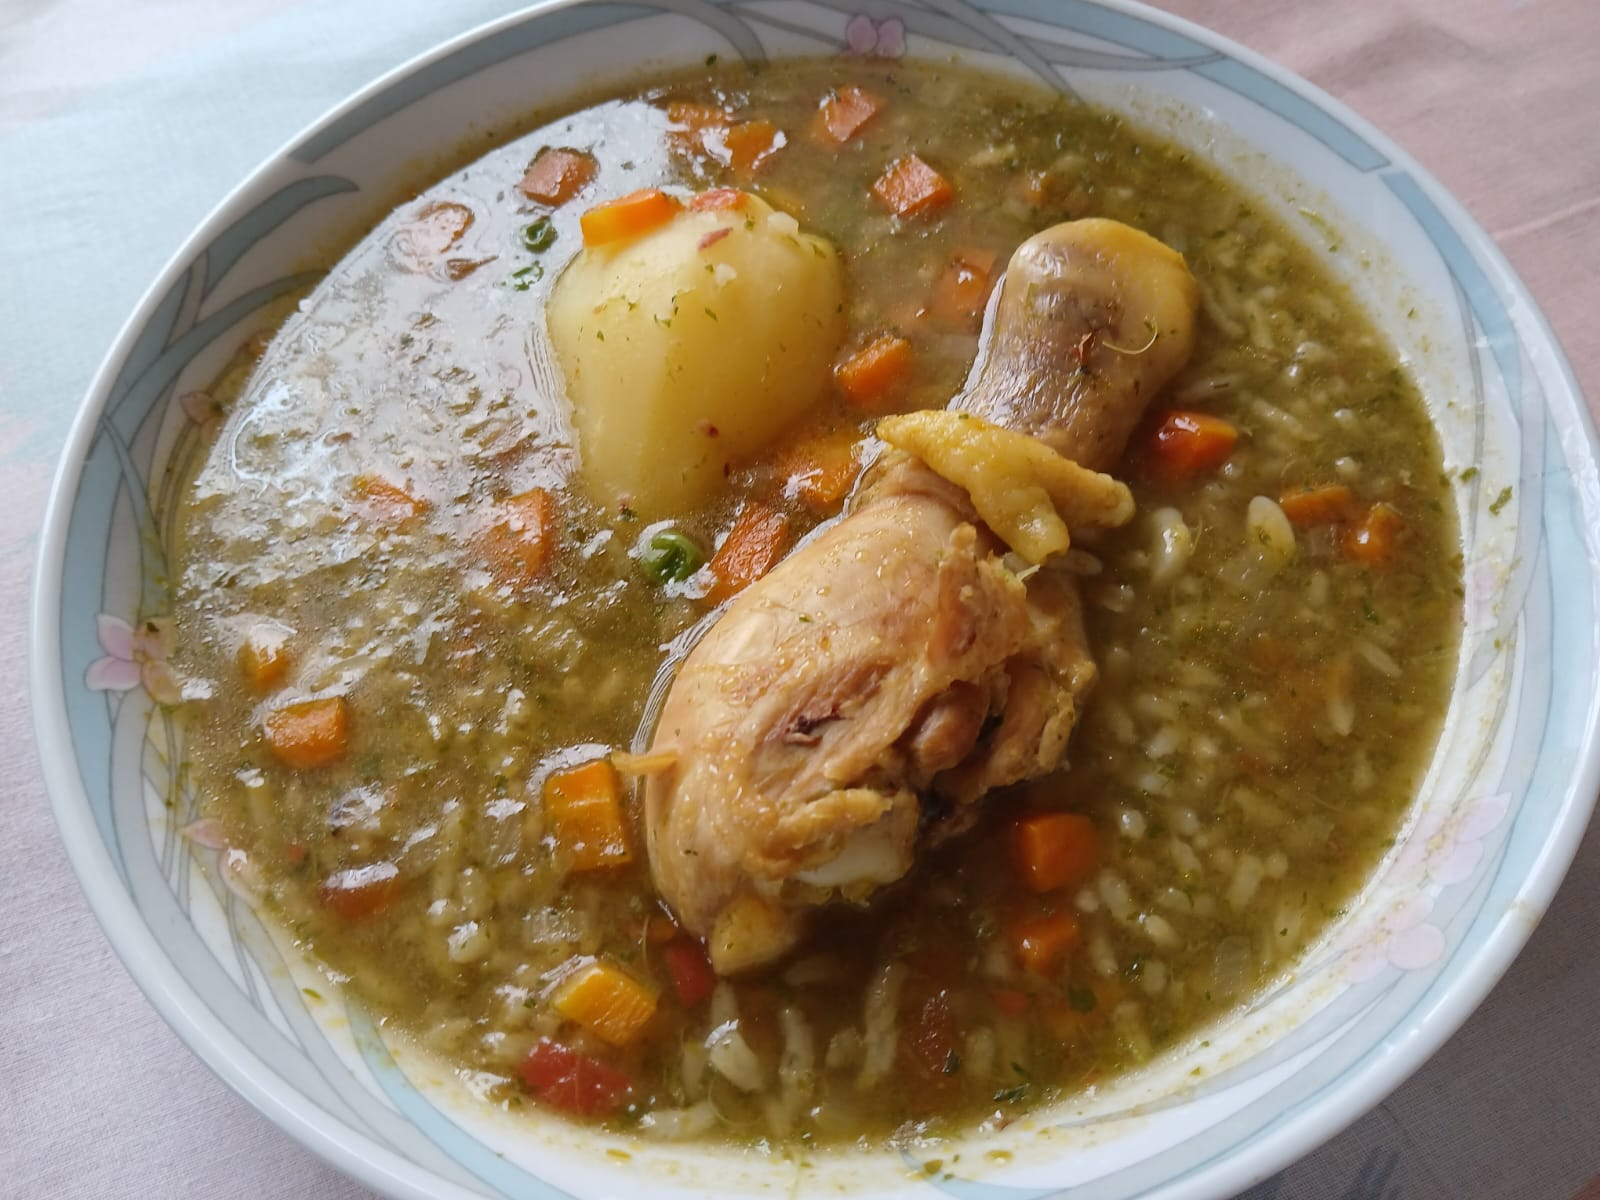

In [5]:
from IPython.display import Image, display

if IMAGE_PATH is None:
    IMAGE_PATH = PROJECT / "data" / "ejemplo_aguadito.jpg"
display(Image(filename=str(IMAGE_PATH), width=500))


La imagen mostrada es la original. Para inferir, el código la convierte a RGB, la redimensiona a 224 × 224 y escala los canales a valores entre 0 y 1; YOLO no aplica la normalización adicional de ImageNet usada por ResNet.

## 4. Proponer una clase

La función de `src/predict.py` reconstruye la arquitectura y procesa una sola imagen. La puntuación softmax indica la fuerza relativa de la clase elegida entre las 40; no es una probabilidad de acierto calibrada. Una puntuación menor que 0,50 se marca como incierta.

In [6]:
import logging
from ultralytics.utils import LOGGER
LOGGER.setLevel(logging.ERROR)
from predict import predict

resultado = predict(IMAGE_PATH, WEIGHTS_PATH, PROJECT / "data" / "classes.json",
                    PROJECT / "data" / "ingredients.json")
print(f"Clase propuesta: {resultado['class_name']}")
print(f"Puntuación: {resultado['score']:.3f}")
print(f"Estado: {'incierto' if resultado['uncertain'] else 'no incierto'}")


Clase propuesta: Aguadito
Puntuación: 0.997
Estado: no incierto


La clase es una propuesta dentro de las 40 conocidas, incluso si la foto muestra otro plato. Un estado no incierto no garantiza que sea correcta.

## 5. Consultar la ficha orientativa

La ficha une las columnas denominadas EFSA y USDA por el estudio para la clase propuesta, sin afirmar que describan regulación vigente. Una lista vacía o una columna sin elementos enumerados no demuestra ausencia.

In [7]:
ficha = resultado["recipe_reference"]
print(f"Receta documentada: {ficha['paper_name']}")
print("Ingredientes orientativos: " + (", ".join(x["name"] for x in ficha["union"]) or "ninguno enumerado"))
print(f"Fuente: {ficha['source']} (tablas 1 y 2)")


Receta documentada: Aguadito
Ingredientes orientativos: Apio
Fuente: https://doi.org/10.1016/j.dib.2025.111604 (tablas 1 y 2)


Las recetas varían y la fotografía **no verifica ingredientes ni contacto cruzado**. Consulte al establecimiento antes de tomar decisiones sobre alergias. Por ejemplo, un error ya documentado clasificó una foto de ají de gallina como locro con puntuación 0,305: cambiar de clase cambia la ficha. Puede consultar `results/test/ejemplo_error.png` y `analisis_errores.json` sin ejecutar otra evaluación.

Para probar una foto propia, modifique `IMAGE_PATH` y ejecute todo otra vez. Si no encuentra la ruta, use una ruta absoluta. Los comandos de reproducción y evaluación están en el README; no use prueba para volver a elegir el modelo.